In [665]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import copy

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import math
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [666]:
df_market = pd.read_csv('../data/preprocessed/model_data.csv')

In [667]:
target_col = "future_rv_20d"

spy_features = [
    "return",
    "log_return",
    "return_5d",
    "return_20d",
    "rv_5d",
    "rv_20d",
    "rv_60d",
    "drawdown",
    "spy_volume",
    "spy_avg_vol_20d"
]

vix_features = [
    "vix_close",
    "vix_pct_change",
    "vix_return_5d",
    "vix_rv_20d",
    "spread",
    "rolling_corr_20d"
]

options_features = [
    # Implied volatility levels
    "atm_iv_14d",
    "atm_iv_30d",
    "atm_iv_60d",
    "atm_iv_90d",

    # Volatility skew
    "rr_25_14d",
    "rr_25_30d",
    "rr_25_60d",
    "rr_25_90d",

    # Volatility smile curvature
    "bf_25_14d",
    "bf_25_30d",
    "bf_25_60d",

    # Term structure
    "atm_term_slope_30_90",

    # IV dynamics
    "atm_iv_30d_change_5d"
]

feature_groups = {
    "SPY": spy_features,
    "SPY + VIX": spy_features + vix_features,
    "SPY + Options": spy_features + options_features,
    "All Features": (
        spy_features + vix_features + options_features
    )
}

In [668]:
LOOKBACK = 60
HORIZON = 20
TARGET = target_col

In [669]:
all_features = list(dict.fromkeys(
    feature
    for group in feature_groups.values()
    for feature in group
))

df = (
    df_market
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

required_columns = all_features + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Check how many dates contain complete information.
complete_mask = df[required_columns].notna().all(axis=1)

print("Original observations:", len(df))
print("Complete observations:", complete_mask.sum())
print(
    "Coverage:",
    f"{complete_mask.mean():.2%}"
)

Original observations: 3258
Complete observations: 2568
Coverage: 78.82%


In [670]:
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

In [671]:
def prepare_feature_data(
    df,
    feature_groups,
    target_col,
    lookback=60,
    horizon=20,
):
    all_features = list(dict.fromkeys(
        col
        for cols in feature_groups.values()
        for col in cols
    ))

    n = len(df)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    feature_valid = (
        df[all_features].notna().all(axis=1)
        .to_numpy()
    )

    target_valid = (
        df[target_col].notna().to_numpy()
    )

    valid_origins = []

    for t in range(lookback - 1, n):

        start = t - lookback + 1

        if not feature_valid[start:t+1].all():
            continue

        if not target_valid[t]:
            continue

        if t < train_end:
            if t + horizon >= train_end:
                continue

        elif t < val_end:
            if t + horizon >= val_end:
                continue

        else:
            if t + horizon >= n:
                continue

        valid_origins.append(t)

    valid_origins = np.array(
        valid_origins, dtype=int
    )

    if len(valid_origins) == 0:
        raise ValueError("No valid sequences found.")

    train_origins = valid_origins[
        valid_origins < train_end
    ]

    if len(train_origins) == 0:
        raise ValueError("No training sequences found.")

    train_row_mask = np.zeros(n, dtype=bool)

    for t in train_origins:
        train_row_mask[
            t - lookback + 1:t + 1
        ] = True

    scaler = StandardScaler()
    scaler.fit(df.loc[train_row_mask, all_features])

    X_scaled = np.full(
        (n, len(all_features)),
        np.nan,
        dtype=np.float32
    )

    X_scaled[feature_valid] = scaler.transform(
        df.loc[feature_valid, all_features]
    ).astype(np.float32)

    y = df[target_col].to_numpy(
        dtype=np.float32
    )

    X_seq = np.stack([
        X_scaled[t-lookback+1:t+1]
        for t in valid_origins
    ])

    y_seq = y[valid_origins]

    split_masks = {
        "train": valid_origins < train_end,
        "val": (
            (valid_origins >= train_end) &
            (valid_origins < val_end)
        ),
        "test": valid_origins >= val_end
    }

    feature_indices = {
        name: [
            all_features.index(col)
            for col in cols
        ]
        for name, cols in feature_groups.items()
    }

    return {
        "X": X_seq,
        "y": y_seq,
        "origins": valid_origins,
        "masks": split_masks,
        "feature_indices": feature_indices,
        "scaler": scaler,
        "all_features": all_features
    }

In [672]:
prepared = prepare_feature_data(
    df=df,
    feature_groups=feature_groups,
    target_col=TARGET,
    lookback=LOOKBACK,
    horizon=HORIZON,
)

print("Sequence shape:", prepared["X"].shape)

Sequence shape: (1335, 60, 29)


In [673]:
def get_group_loaders(
    prepared,
    group_name,
    batch_size=32
):
    indices = prepared["feature_indices"][group_name]

    X_group = prepared["X"][:, :, indices]
    y = prepared["y"]

    loaders = {}

    for split in ["train", "val", "test"]:
        mask = prepared["masks"][split]

        X_tensor = torch.from_numpy(
            np.ascontiguousarray(X_group[mask])
        )

        y_tensor = torch.from_numpy(
            np.ascontiguousarray(y[mask])
        )

        dataset = TensorDataset(
            X_tensor,
            y_tensor
        )

        loaders[split] = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=(split == "train")
        )

    return loaders

In [674]:
loaders = get_group_loaders(
    prepared,
    "SPY + Options"
)

train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]

In [675]:
def set_feature_group(feature_names):
    features = feature_groups[feature_names]

    df = (
        df_market
        .sort_values("date")
        .reset_index(drop=True)
        .copy()
    )

    df = df.dropna(subset=features + [TARGET]).copy()

    n = len(df)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    scaler = StandardScaler()
    scaler.fit(df.iloc[:train_end][features])

    X_all = scaler.transform(df[features]).astype(
        np.float32
    )

    y_all = df[TARGET].to_numpy(dtype=np.float32)

    return {'train_end': train_end, 'val_end': val_end, 'X_all': X_all, 'y_all': y_all}

In [676]:
def create_sequences(X, y, lookback):
    X_seq = []
    y_seq = []
    origins = []
    for t in range(lookback-1, len(X)):
        X_seq.append(X[t-lookback+1:t+1])
        y_seq.append(y[t])
        origins.append(t)

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(origins)
    )

In [677]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)

        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)

        pe[:, 1::2] = torch.cos(div_term * position)

        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [678]:
class VolatilityTransformer(nn.Module):
    def __init__(
            self,
            num_features,
            d_model=64,
            nhead=4,
            num_layers=2,
            dim_feedforward=128,
            dropout=0.2
    ):
        super().__init__()

        self.input_projection = nn.Linear(num_features, d_model)

        self.pos_encoder = PositionalEncoding(d_model=d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=False
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=True
        )

        self.norm = nn.LayerNorm(d_model)

        self.regressor = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.input_projection(x)

        x = self.pos_encoder(x)

        x = self.transformer(x)

        #Rep of most recent day
        x = x[:, -1, :]

        x = self.norm(x)

        output = self.regressor(x)

        return output.squeeze(-1)

In [679]:
def train_model(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        device,
        epochs=100,
):
    history = {
        'train_mae': [],
        'val_mae': []
    }

    best_val = float("inf")
    best_state = None

    for epoch in range(epochs):
        model.train()
        train_err = 0.0
        train_count = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            optimizer.step()

            train_err += (loss.item() * len(y_batch))

            train_count += len(y_batch)

        train_mae = train_err / train_count

        model.eval()
        val_err = 0.0
        val_count = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = model(X_batch)

                loss = criterion(predictions, y_batch)

                val_err += loss.item() * len(y_batch)

                val_count += len(y_batch)

        val_mae = val_err/ val_count

        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_mae < best_val:
            best_val = val_mae
            best_state = copy.deepcopy(model.state_dict())

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch+1:03d} | "
                f"Train MAE: {train_mae:.6f} | "
                f"Val MAE: {val_mae:.6f}"
            )

    model.load_state_dict(best_state)

    return model, history

In [680]:
def predict_model(model, loader, device):
    model.eval()
    predictions = []
    targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)

            pred = model(X_batch)

            predictions.extend(pred.cpu().numpy())
            targets.extend(y_batch.numpy())

    return np.array(targets), np.array(predictions)

In [681]:
def run_models(
    prepared,
    feature_groups,
    device,
    epochs=100,
    seed=42
):
    results = []
    models = {}
    histories = {}
    predictions = {}

    for feature_group in feature_groups:
        print(f"\n{'='*50}")
        print(f"Training: {feature_group}")
        print(f"{'='*50}")

        torch.manual_seed(seed)

        loaders = get_group_loaders(
            prepared=prepared,
            group_name=feature_group,
        )

        num_features = len(prepared['feature_indices'][feature_group])

        model = VolatilityTransformer(
            num_features=num_features,
            d_model=64,
            nhead=4,
            num_layers=2,
            dim_feedforward=128,
            dropout=0.3
        ).to(device)

        optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-2)
        criterion = nn.L1Loss()

        model, history = train_model(
            model,
            loaders["train"],
            loaders["val"],
            criterion,
            optimizer,
            device,
            epochs=epochs,
        )

        y_true, y_pred = predict_model(
            model,
            loaders["val"],
            device
        )

        val_mae = mean_absolute_error(y_true, y_pred)

        results.append({
            "Feature Group": feature_group,
            "Features": num_features,
            "Validation MAE": val_mae,
            "Best Epoch": (
                np.argmin(history["val_mae"]) + 1
            ),
            "Seed": seed
        })

        histories[feature_group] = history

        models[feature_group] = copy.deepcopy(model.state_dict())

        predictions[feature_group] = y_pred

        filename = (
            "transformer_"
            + feature_group.lower()
                .replace(" + ", "_")
                .replace(" ", "_")
            + ".pth"
        )

        torch.save({
            "model_state_dict": model.state_dict(),
            "history": history,
            "feature_names": feature_groups[feature_group],
            "val_mae": val_mae,
            "seed": seed
        }, filename)

        print(
            f"{feature_group}: "
            f"Validation MAE = {val_mae:.6f}"
        )

    results_df = pd.DataFrame(results).sort_values('Validation MAE').reset_index(drop=True)

    return results_df, models, histories, predictions

In [682]:
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu'
)

results = []
seeds = [42, 123, 456, 789, 2026]
for seed in seeds:
    run_df, models, histories, predictions = (
        run_models(
            prepared,
            feature_groups,
            device,
            seed=seed
        )
    )
    results.append(run_df)

results_df = pd.concat(results, ignore_index=True)
display(results_df)

seed_df = results_df.pivot(
    index='Seed',
    columns='Feature Group',
    values='Validation MAE'
)
display(seed_df)


Training: SPY
Epoch 001 | Train MAE: 0.159042 | Val MAE: 0.154861
Epoch 010 | Train MAE: 0.060053 | Val MAE: 0.119742
Epoch 020 | Train MAE: 0.053346 | Val MAE: 0.112461
Epoch 030 | Train MAE: 0.049669 | Val MAE: 0.114716
Epoch 040 | Train MAE: 0.048768 | Val MAE: 0.112800
Epoch 050 | Train MAE: 0.045007 | Val MAE: 0.117136
Epoch 060 | Train MAE: 0.043401 | Val MAE: 0.114295
Epoch 070 | Train MAE: 0.043499 | Val MAE: 0.116764
Epoch 080 | Train MAE: 0.041180 | Val MAE: 0.109265
Epoch 090 | Train MAE: 0.041536 | Val MAE: 0.108305
Epoch 100 | Train MAE: 0.039537 | Val MAE: 0.105775
SPY: Validation MAE = 0.103115

Training: SPY + VIX
Epoch 001 | Train MAE: 0.090803 | Val MAE: 0.092586
Epoch 010 | Train MAE: 0.054853 | Val MAE: 0.079436
Epoch 020 | Train MAE: 0.043960 | Val MAE: 0.075142
Epoch 030 | Train MAE: 0.039016 | Val MAE: 0.075752
Epoch 040 | Train MAE: 0.036220 | Val MAE: 0.074244
Epoch 050 | Train MAE: 0.034348 | Val MAE: 0.075832
Epoch 060 | Train MAE: 0.034241 | Val MAE: 0.0761

,Feature Group,Features,Validation MAE,Best Epoch,Seed
0,SPY + VIX,16,0.072528,22,42
1,All Features,29,0.074122,8,42
2,SPY + Options,23,0.080637,10,42
3,SPY,10,0.103115,89,42
4,SPY + VIX,16,0.079211,65,123
5,All Features,29,0.084174,34,123
6,SPY,10,0.085670,3,123
7,SPY + Options,23,0.102280,99,123
8,SPY + VIX,16,0.078749,59,456
9,SPY + Options,23,0.081967,5,456


Feature Group,All Features,SPY,SPY + Options,SPY + VIX
Seed,,,,
42,0.074122,0.103115,0.080637,0.072528
123,0.084174,0.085670,0.102280,0.079211
456,0.083175,0.085949,0.081967,0.078749
789,0.076674,0.086778,0.077450,0.081043
2026,0.092877,0.086420,0.097614,0.080533


In [686]:
summary = (
    results_df
    .groupby("Feature Group")["Validation MAE"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean")
)

print(summary)

                   mean       std       min       max
Feature Group                                        
SPY + VIX      0.078413  0.003420  0.072528  0.081043
All Features   0.082204  0.007325  0.074122  0.092877
SPY + Options  0.087990  0.011161  0.077450  0.102280
SPY            0.089586  0.007575  0.085670  0.103115


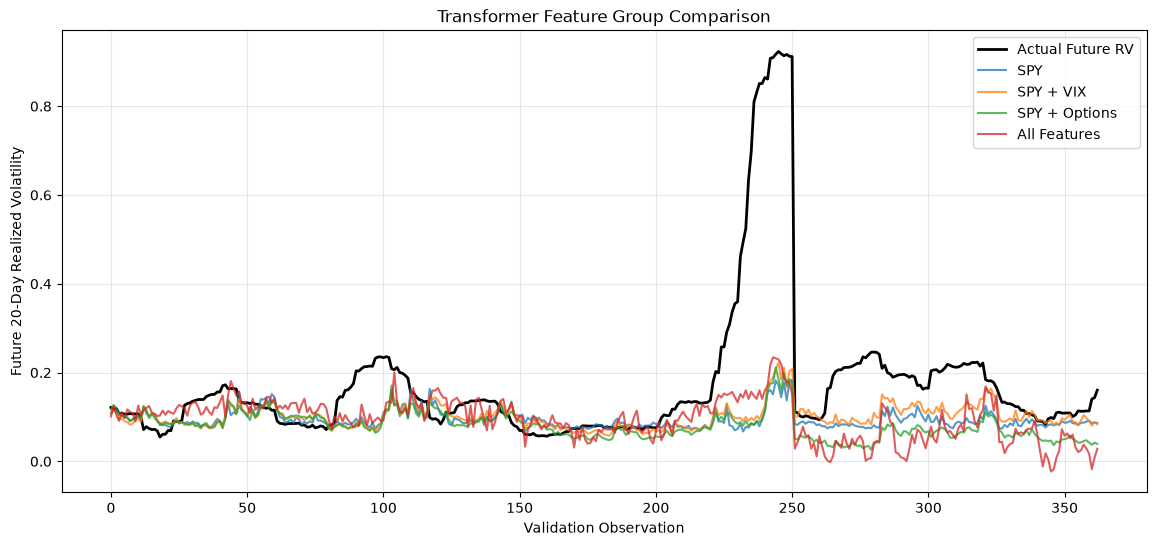

In [683]:
val_mask = prepared["masks"]["val"]

y_val = prepared["y"][val_mask]

plt.figure(figsize=(14, 6))

plt.plot(
    y_val,
    label="Actual Future RV",
    color="black",
    linewidth=2
)

for group_name, y_pred in predictions.items():
    plt.plot(
        y_pred,
        label=group_name,
        alpha=0.75
    )

plt.title("Transformer Feature Group Comparison")
plt.xlabel("Validation Observation")
plt.ylabel("Future 20-Day Realized Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

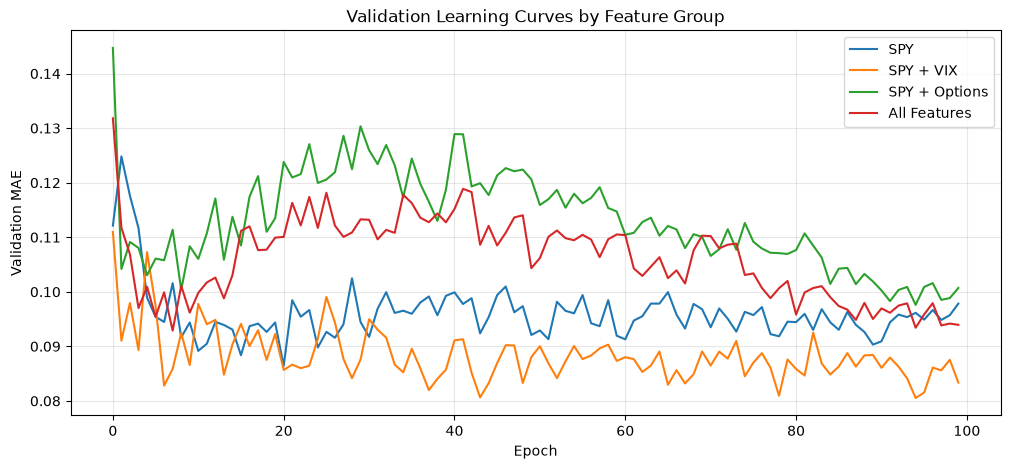

In [684]:
plt.figure(figsize=(12, 5))

for group_name, history in histories.items():
    plt.plot(
        history["val_mae"],
        label=group_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title("Validation Learning Curves by Feature Group")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

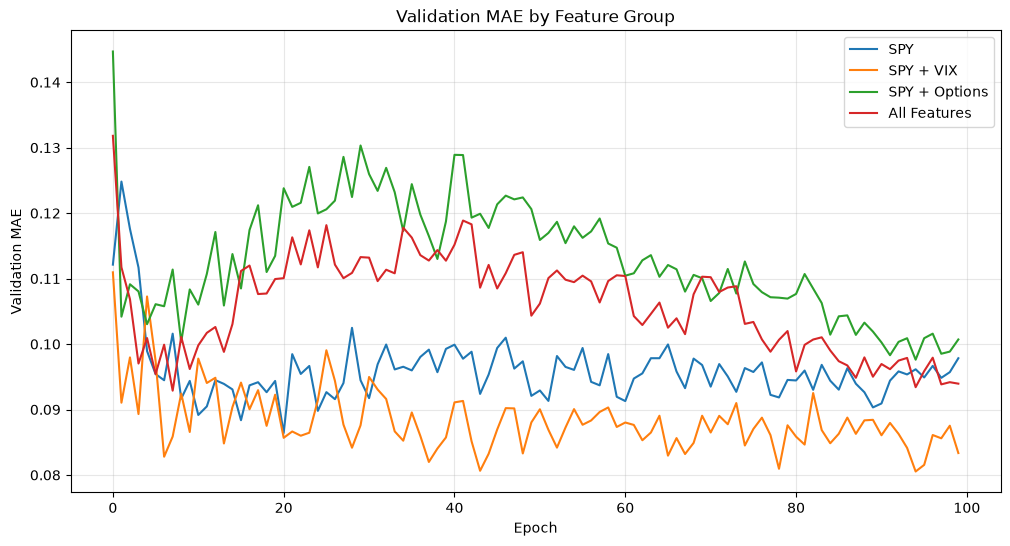

In [685]:
plt.figure(figsize=(12, 6))

for group_name, history in histories.items():
    plt.plot(
        history["val_mae"],
        label=group_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title("Validation MAE by Feature Group")
plt.legend()
plt.grid(alpha=0.3)
plt.show()